# Ga for tuning the h-p

In this notebook I will tune only the activation function 

## The NN

In [61]:
# Libs

import torch # the main pytorch library
from torch import nn # the sub-library containing neural networks
from torch.utils.data import DataLoader, Subset # an object that generates batches of data for training/testing
from torchvision import datasets # popular datasets, architectures and common image transformations
from torchvision.transforms import ToTensor # an easy way to convert PIL images to Tensors

import numpy as np # NumPy, the python array library
import random # for generating random numbers
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, random_split


In [62]:
# Set seeds

SEED = 0 # seed for reproducibility

random.seed(SEED) # set the seed for random numbers
np.random.seed(SEED) # set the seed for numpy arrays

In [63]:
# Download training data
# Build validation data
# Download test data

# Parameters
validation_ratio = 0.2

# Download training data from open datasets
training_data = datasets.FashionMNIST(
    root="data",  # data is downloaded to this folder
    train=True,  # this is the training data
    download=True,  # download if data is not found locally
    transform=ToTensor(),  # convert the image to a PyTorch tensor
)


# Split dataset into training and validation sets
# train and validation data
num_samples = len(training_data)
num_validation_samples = int(validation_ratio * num_samples)
num_training_samples = num_samples - num_validation_samples

# First num_training_samples are for training 
# Last num_validation_samples are for validation
train_data = Subset(training_data, range(num_training_samples))
validation_data = Subset(training_data, range(num_training_samples, num_samples))



# Download test data from open datasets
test_data = datasets.FashionMNIST(
    root="data",  # data is downloaded to this folder
    train=False,  # this is the test data
    download=True,  # download if data is not found locally
    transform=ToTensor(),  # convert the image to a PyTorch tensor
)


In [64]:
# Define data loader (specifing batch size)

batch_size = 64 # the size of input data took for one iteration

# Create data loaders.
# Create data loaders
train_dataloader = DataLoader(train_data, batch_size=batch_size)
validation_dataloader = DataLoader(validation_data, batch_size=batch_size)
test_dataloader = DataLoader(test_data, batch_size=batch_size)

# N is batch size; 
# C is number of channels;
# H is height of image; 
# W is width of image
for X, y in train_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

for X, y in validation_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

for X, y in test_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break



Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64


In [65]:
# Set the device 
device = ( # check if gpu is available
    "cuda"
    if torch.cuda.is_available() # use gpu
    else "mps" # use mps
    if torch.backends.mps.is_available() # use mps
    else "cpu" # use cpu
)
print(f"Using {device} device\n")

Using cpu device



In [66]:
# A model in which you can specify: 
# the number of hidden units,
# the activation function,
# whether to initialize the weights or not

class flexible_NN_units(nn.Module): # define a neural network class
    def __init__(self, 
                 input_size = 28*28,
                 hidden_size1 = 512,
                 hidden_size2 = 512,
                 output_size = 10,
                 activation_function = nn.ReLU,
                 initialize_weights = False): # initialisation method
        super().__init__() # initialise the neural network
        self.flatten = nn.Flatten() # flatten (appiattire) the input image
        self.activation_function = activation_function()
        self.linear_relu_stack = nn.Sequential( # create a sequence of layers
            nn.Linear(input_size, hidden_size1), # linear layer from 28*28 to 512 (28*28 is the size of the input image, 512 is the size of the output tensor)
            self.activation_function,  # activation function
            nn.Linear(hidden_size1, hidden_size2), # linear layer from 512 to 512 (512 is the size of the input tensor, 512 is the size of the output tensor)
            self.activation_function, # activation function
            nn.Linear(hidden_size2, output_size) # linear layer from 512 to 10 (512 is the size of the input tensor, 10 is the size of the output tensor)
        )
        if initialize_weights:
            self._initialize_weights()

    def forward(self, x): # forward method
        x = self.flatten(x) # flatten the input image
        logits = self.linear_relu_stack(x) # pass the input image through the sequence of layers
        return logits # return the output tensor
    
    def _initialize_weights(self):
      for m in self.modules():
          if isinstance(m, nn.Linear):
              nn.init.xavier_uniform_(m.weight)
              nn.init.zeros_(m.bias)



# A model in which you can specify: 
# the number of hidden layers and units,
# the activation function,
# whether to initialize the weights or not


class flexible_NN_layers(nn.Module): # define a neural network class
    def __init__(self, 
                 input_size = 28*28,
                 hidden_sizes = [512,512],
                 output_size = 10,
                 activation_function = nn.ReLU,
                 initialize_weights = False): # initialisation method
        super().__init__() # initialise the neural network
        self.flatten = nn.Flatten() # flatten (appiattire) the input image
        self.activation_function = activation_function()

        # Create a list to hold the layers
        layers = []
        previous_size = input_size

        # Add hidden layers dynamically
        for hidden_size in hidden_sizes:
            layers.append(nn.Linear(previous_size, hidden_size))
            layers.append(self.activation_function)
            previous_size = hidden_size
        layers.append(nn.Linear(previous_size, output_size)) # Add the final output layer

        # Create a sequential container with the layers
        # You shoould pass a list of layers to the Sequential container, one by one. 
        # You can do this by using the * operator to unpack the list of layers
        # This is done to avoid of passing a list of layers to the Sequential container (that is not correct)
        self.linear_relu_stack = nn.Sequential(*layers)
      
        if initialize_weights:
            self._initialize_weights()

    def forward(self, x): # forward method
        x = self.flatten(x) # flatten the input image
        logits = self.linear_relu_stack(x) # pass the input image through the sequence of layers
        return logits # return the output tensor
    
    def _initialize_weights(self):
      for m in self.modules():
          if isinstance(m, nn.Linear):
              nn.init.xavier_uniform_(m.weight)
              nn.init.zeros_(m.bias)

In [67]:
# Train and test functions

def train(dataloader, model, loss_fn, optimizer): # create a training function
    size = len(dataloader.dataset) # get the size of the dataset
    model.train() # set the model to training mode
    train_loss = 0.0 # initialise the training loss
    for batch, (X, y) in enumerate(dataloader): # iterate over the data
        X, y = X.to(device), y.to(device) # send the input data to the device

        # Compute prediction error
        pred = model(X) # get the model's prediction
        loss = loss_fn(pred, y) # compute the loss (between the model's prediction and the actual value)

        # Backpropagation
        loss.backward() # backpropagate the loss
        optimizer.step() # adjust the model parameters
        optimizer.zero_grad() # reset the gradients

        train_loss += loss.item()

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X) # get the loss and the current batch
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")
    
    train_loss /= len(dataloader)
    return train_loss




def test(dataloader, model, loss_fn): # create a test function
    size = len(dataloader.dataset)
    num_batches = len(dataloader) # get the number of batches
    model.eval() # set the model to evaluation mode (test correspondece of model.train())
    test_loss, correct = 0, 0 # initialise the test loss and the number of correct predictions
    with torch.no_grad(): # disable gradient calculation
        for X, y in dataloader: # iterate over the data
            X, y = X.to(device), y.to(device) # send the input data to the device
            pred = model(X) # get the model's prediction
            test_loss += loss_fn(pred, y).item() # compute the loss
            correct += (pred.argmax(1) == y).type(torch.float).sum().item() # compute the number of correct predictions
    test_loss /= num_batches # compute the average loss
    correct /= size # compute the accuracy
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")
    return test_loss, 100*correct



# All in one function

def train_and_test_model(epochs, model, loss_fn, optimizer, train_dataloader, test_dataloader):
    train_loss_history = []
    test_loss_history = []
    accuracy_history = []

    for t in range(epochs):
        print(f"Epoch {t+1}\n-------------------------------")
        train_loss = train(train_dataloader, model, loss_fn, optimizer)
        test_loss, accuracy = test(test_dataloader, model, loss_fn)

        train_loss_history.append(train_loss)
        test_loss_history.append(test_loss)
        accuracy_history.append(accuracy)

    print("Done!")
    return train_loss_history, test_loss_history, accuracy_history


## The EA 

In [68]:
class Individual:
    def __init__(self, gene, fitness=0.0):
        """
        Initialize an individual with a gene, solution, and fitness.
        
        Parameters:
        gene (float): The value in the space of the gene.
        solution (Any): The value in the space of the solution.
        fitness (float): The fitness value of the individual.
        """
        self.gene = gene
        self.solution = self.from_gene_to_solution(gene)
        self.fitness = fitness

    def from_gene_to_solution(self, g):
        if g == 0:
            return nn.ReLU
        elif g == 1:
            return nn.Tanh
        elif g == 2:
            return nn.Sigmoid
        elif g == 3:
            return nn.LeakyReLU
        elif g == 4:
            return nn.PReLU
        else:
            return None
    
    def __repr__(self):
        return f"Gene: {self.gene}, Solution: {self.solution}, Fitness: {self.fitness}"

# Example usage:
individual1 = Individual(gene=0)
individual2 = Individual(gene=1)

print(f"Individual 1: {individual1}")
print(f"Individual 2: {individual2}")


Individual 1: Gene: 0, Solution: <class 'torch.nn.modules.activation.ReLU'>, Fitness: 0.0
Individual 2: Gene: 1, Solution: <class 'torch.nn.modules.activation.Tanh'>, Fitness: 0.0


In [69]:
def initialization(population_size=5, activation_functions_gene_space=[0, 1, 2, 3, 4]):
    
    genes = np.random.choice(activation_functions_gene_space, population_size)
    individuals = [Individual(gene=g) for g in genes]

    return individuals

# Example usage:
population_size = 5
population = initialization(population_size)

for individual in population:
    print(individual)

Gene: 4, Solution: <class 'torch.nn.modules.activation.PReLU'>, Fitness: 0.0
Gene: 0, Solution: <class 'torch.nn.modules.activation.ReLU'>, Fitness: 0.0
Gene: 3, Solution: <class 'torch.nn.modules.activation.LeakyReLU'>, Fitness: 0.0
Gene: 3, Solution: <class 'torch.nn.modules.activation.LeakyReLU'>, Fitness: 0.0
Gene: 3, Solution: <class 'torch.nn.modules.activation.LeakyReLU'>, Fitness: 0.0


In [70]:
def fitness_evaluation(
        individual,
        training_data,
        validation_data,
        num_epochs_per_evaluation=5,
        lr = 0.0096,
        input_size = 28*28,
        hidden_sizes = [512,512],
        output_size = 10,
        initialize_weights = False
        ):

    # Set the device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    # Activate the specified activation function
    activation_function = individual.solution
    
    # Create a new model
    model = flexible_NN_layers(
        input_size=input_size,
        hidden_sizes=hidden_sizes,
        output_size=output_size,
        activation_function=activation_function,
        initialize_weights=initialize_weights).to(device)
    
    # Define loss function
    loss_fn = nn.CrossEntropyLoss()
    
    # Create a new optimizer with the specified learning rate
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    
    
    # Train the model for the specified number of epochs
    for _ in range(num_epochs_per_evaluation):
        model.train()
        for X, y in training_data:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            loss = loss_fn(pred, y)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
    
    # Compute the validation loss
    model.eval()
    validation_loss = 0
    with torch.no_grad():
        for X, y in validation_data:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            loss = loss_fn(pred, y)
            validation_loss += loss.item()
    
    # Average validation loss over all batches
    validation_loss /= len(validation_data)
    
    return validation_loss


# Example usage:
individual = population[0]
fitness = fitness_evaluation(
    individual,
    train_dataloader,
    validation_dataloader,
    num_epochs_per_evaluation=5)

print(f"Individual: {individual}")
print(f"Fitness of individual: {fitness}")

KeyboardInterrupt: 

In [ ]:
# Assess population
def evaluate_population(
        population,
        training_data,
        validation_data,
        num_epochs_per_evaluation=5,
        lr = 0.0096,
        input_size = 28*28,
        hidden_sizes = [512,512],
        output_size = 10,
        initialize_weights = False):
    
    for individual in population:
        individual.fitness = fitness_evaluation(
            individual,
            training_data,
            validation_data,
            num_epochs_per_evaluation,
            lr,
            input_size,
            hidden_sizes,
            output_size,
            initialize_weights)
    

# Example usage:
evaluate_population(
    population,
    train_dataloader,
    validation_dataloader,
    num_epochs_per_evaluation=5)

for individual in population:
    print(individual)

Gene: 0, Solution: <class 'torch.nn.modules.activation.ReLU'>, Fitness: 0.4986950414294892
Gene: 2, Solution: <class 'torch.nn.modules.activation.Sigmoid'>, Fitness: 1.4839149415493011
Gene: 3, Solution: <class 'torch.nn.modules.activation.LeakyReLU'>, Fitness: 0.4973399705709295
Gene: 0, Solution: <class 'torch.nn.modules.activation.ReLU'>, Fitness: 0.49927309694442346
Gene: 1, Solution: <class 'torch.nn.modules.activation.Tanh'>, Fitness: 0.48625109630062224


In [ ]:
def find_best_individual(population):
    """
    Find the individual with the best fitness value in the population.
    
    Parameters:
    population (list): A list of Individual objects.
    
    Returns:
    Individual: The individual with the best fitness value.
    """
    best_individual = min(population, key=lambda x: x.fitness)
    return best_individual

# Example usage:
best_individual = find_best_individual(population)
print(best_individual)

Gene: 1, Solution: <class 'torch.nn.modules.activation.Tanh'>, Fitness: 0.48625109630062224


In [ ]:
# Roulette wheel selection (pay attention that the gretaer the fitness, the lower the probability of selection)
def roulette_wheel_selection(population, best_individual, num_to_select):
    remaining_population = [ind for ind in population if ind != best_individual]

    # Invert fitness values for selection probability calculation
    max_fitness = max(ind.fitness for ind in remaining_population)
    selection_values = [max_fitness - ind.fitness for ind in remaining_population]

    # Normalize selection values to probabilities
    total_selection_value = sum(selection_values)
    selection_probs = [value / total_selection_value for value in selection_values]

    selected_indices = np.random.choice(len(remaining_population), size=num_to_select, replace=True, p=selection_probs)
    selected_individuals = [remaining_population[i] for i in selected_indices]
    
    return selected_individuals

# Example 
roulette_selected = roulette_wheel_selection(population, best_individual, 3)
for ind in roulette_selected:
    print(ind)

Gene: 3, Solution: <class 'torch.nn.modules.activation.LeakyReLU'>, Fitness: 0.4973399705709295
Gene: 0, Solution: <class 'torch.nn.modules.activation.ReLU'>, Fitness: 0.49927309694442346
Gene: 0, Solution: <class 'torch.nn.modules.activation.ReLU'>, Fitness: 0.4986950414294892


In [ ]:
# Maintain the individual with the best fitness value
def deterministic_best_class(parent1,parent2):
    if parent1.fitness < parent2.fitness:
        offspring = Individual(gene=parent1.gene)
    else:
        offspring = Individual(gene=parent2.gene)  
    return offspring

# Maintain the individual with the best fitness value but with a probability of choosing the worse parent
def stochastic_best_class(parent1,parent2, mutation_rate=0.1):
    if np.random.rand() > mutation_rate:
        if parent1.fitness < parent2.fitness:
            offspring = Individual(gene=parent1.gene)
        else:
            offspring = Individual(gene=parent2.gene)
    else:
        if parent1.fitness < parent2.fitness:
            offspring = Individual(gene=parent2.gene)
        else:
            offspring = Individual(gene=parent1.gene)
    return offspring

# Exmaple usage
parent1 = population[0]
parent2 = population[1]
offspring1 = deterministic_best_class(parent1, parent2)
offspring2 = stochastic_best_class(parent1, parent2, mutation_rate=0.1)

print(f"Parent 1: {parent1}")
print(f"Parent 2: {parent2}")
print(f"Offspring of deterministic CX: {offspring1}")
print(f"Offspring of stochastic CX: {offspring2}")

Parent 1: Gene: 0, Solution: <class 'torch.nn.modules.activation.ReLU'>, Fitness: 0.4986950414294892
Parent 2: Gene: 2, Solution: <class 'torch.nn.modules.activation.Sigmoid'>, Fitness: 1.4839149415493011
Offspring of deterministic CX: Gene: 0, Solution: <class 'torch.nn.modules.activation.ReLU'>, Fitness: 0.0
Offspring of stochastic CX: Gene: 0, Solution: <class 'torch.nn.modules.activation.ReLU'>, Fitness: 0.0


In [ ]:
# Mutation
def mutation(individual, mutation_rate=0.1, activation_functions_gene_space=[0, 1, 2, 3, 4]):
    offspring = individual
    if np.random.rand() < mutation_rate:
        new_gene = np.random.choice(activation_functions_gene_space)
        offspring = Individual(gene=new_gene)
    return offspring

# Example usage
individual = population[0]
mutated_individual = mutation(individual, mutation_rate=0.5)

print(f"Individual: {individual}")
print(f"Mutated individual: {mutated_individual}")

Individual: Gene: 0, Solution: <class 'torch.nn.modules.activation.ReLU'>, Fitness: 0.4986950414294892
Mutated individual: Gene: 3, Solution: <class 'torch.nn.modules.activation.LeakyReLU'>, Fitness: 0.0


In [ ]:
def create_new_population(parents, population_size, mutation_probability=0.1):
    """
    Create a new population by applying crossover and mutation on the parents.
    
    Parameters:
    parents (list of Individual): The list of parent individuals.
    population_size (int): The desired size of the new population.
    mutation_probability (float): The probability of applying mutation to an offspring.
    
    Returns:
    list of Individual: The new population of individuals.
    """
    new_population = []
    
    while len(new_population) < population_size - 1:
        # Select two random parents for crossover
        parent1, parent2 = np.random.choice(parents, 2, replace=False)
        # Perform crossover
        offspring = deterministic_best_class(parent1, parent2)
        # Apply mutation with a certain probability
        offspring = mutation(offspring, mutation_probability)
        # Add the offspring to the new population
        new_population.append(offspring)
    
    return new_population

# Example usage:
parents = roulette_selected
parents.append(best_individual)

new_population = create_new_population(parents, population_size)
new_population.append(best_individual)

for ind in new_population:
    print(ind)

Gene: 1, Solution: <class 'torch.nn.modules.activation.Tanh'>, Fitness: 0.0
Gene: 1, Solution: <class 'torch.nn.modules.activation.Tanh'>, Fitness: 0.0
Gene: 1, Solution: <class 'torch.nn.modules.activation.Tanh'>, Fitness: 0.0
Gene: 0, Solution: <class 'torch.nn.modules.activation.ReLU'>, Fitness: 0.0
Gene: 1, Solution: <class 'torch.nn.modules.activation.Tanh'>, Fitness: 0.48625109630062224


In [ ]:
# Ea for finding the best actiavtion function 

def ga_for_af(
        max_fitness_evaluations, # 50 is suggested 
        population_size=5,
        activation_functions_gene_space=[0, 1, 2, 3, 4],
        train_dataloader=train_dataloader,
        validation_dataloader=validation_dataloader,
        num_epochs_per_evaluation=5,
        lr = 0.0096,
        input_size = 28*28,
        hidden_sizes = [512,512],
        output_size = 10,
        initialize_weights = False,
        num_roulette_selected=3,
        mutation_probability=0.1
        ):
    
    # Initialize the population
    fitness_evaluations = 0
    gen_index = 1
    population = initialization(population_size, activation_functions_gene_space)
    fitness_evaluations += population_size
    evaluate_population(
        population,
        train_dataloader,
        validation_dataloader,
        num_epochs_per_evaluation=num_epochs_per_evaluation,
        lr = lr,
        input_size = input_size,
        hidden_sizes = hidden_sizes,
        output_size = output_size,
        initialize_weights = initialize_weights)
    best_individual = find_best_individual(population)
    print(f"Generation: {gen_index} | Fitness evalutions: {fitness_evaluations} | Best individual: {best_individual}")

    while fitness_evaluations < max_fitness_evaluations:
        # Select parents using roulette wheel selection
        parents = roulette_wheel_selection(population, best_individual, num_roulette_selected)
        # Add the best individual to the parents
        parents.append(best_individual)
        # Create a new population through crossover and mutation
        population = create_new_population(parents, population_size, mutation_probability)
        population.append(best_individual)
        # Evaluate the new population
        evaluate_population(
            population,
            train_dataloader,
            validation_dataloader,
            num_epochs_per_evaluation=num_epochs_per_evaluation,
            lr = lr,
            input_size = input_size,
            hidden_sizes = hidden_sizes,
            output_size = output_size,
            initialize_weights = initialize_weights)
        fitness_evaluations += population_size

        # Find the best individual in the new population
        best_individual = find_best_individual(population)
        print(f"Generation: {gen_index + 1} | Fitness evalutions: {fitness_evaluations} | Best individual: {best_individual}")
        gen_index += 1

    return best_individual

In [ ]:
# Example usage:
best_individual = ga_for_af(
    max_fitness_evaluations=50,
    population_size=5,
    activation_functions_gene_space=[0, 1, 2, 3, 4],
    train_dataloader=train_dataloader,
    validation_dataloader=validation_dataloader,
    num_epochs_per_evaluation=5,
    lr = 0.0096,
    input_size = 28*28,
    hidden_sizes = [512,512],
    output_size = 10,
    initialize_weights = False,
    num_roulette_selected=3,
    mutation_probability=0.1)

print(f"Best individual: {best_individual}")


Generation: 1 | Fitness evalutions: 5 | Best individual: Gene: 4, Solution: <class 'torch.nn.modules.activation.PReLU'>, Fitness: 0.42638610390589593
Generation: 2 | Fitness evalutions: 10 | Best individual: Gene: 4, Solution: <class 'torch.nn.modules.activation.PReLU'>, Fitness: 0.4262552433349985
Generation: 3 | Fitness evalutions: 15 | Best individual: Gene: 4, Solution: <class 'torch.nn.modules.activation.PReLU'>, Fitness: 0.42341165728074437
Generation: 4 | Fitness evalutions: 20 | Best individual: Gene: 4, Solution: <class 'torch.nn.modules.activation.PReLU'>, Fitness: 0.42423080946219727
Generation: 5 | Fitness evalutions: 25 | Best individual: Gene: 4, Solution: <class 'torch.nn.modules.activation.PReLU'>, Fitness: 0.4234410250916126
Generation: 6 | Fitness evalutions: 30 | Best individual: Gene: 4, Solution: <class 'torch.nn.modules.activation.PReLU'>, Fitness: 0.4269305563512001
Generation: 7 | Fitness evalutions: 35 | Best individual: Gene: 4, Solution: <class 'torch.nn.modu

## Tests

In [71]:
# Train and test model 

epochs = 15
model = flexible_NN_layers(
    input_size=28*28,
    hidden_sizes=[512,512],
    output_size=10,
    activation_function=nn.ReLU,
    initialize_weights=False).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.0096)

std_train_loss_history, std_test_loss_history, std_accuracy_history = train_and_test_model(
    epochs, 
    model,
    loss_fn,
    optimizer,
    train_dataloader,
    test_dataloader)

Epoch 1
-------------------------------
loss: 2.308998  [   64/48000]
loss: 2.181693  [ 6464/48000]
loss: 1.865530  [12864/48000]
loss: 1.574314  [19264/48000]
loss: 1.217399  [25664/48000]
loss: 1.100189  [32064/48000]
loss: 1.044556  [38464/48000]
loss: 0.901736  [44864/48000]
Test Error: 
 Accuracy: 67.7%, Avg loss: 0.891724 

Epoch 2
-------------------------------
loss: 0.931800  [   64/48000]
loss: 0.935312  [ 6464/48000]
loss: 0.677221  [12864/48000]
loss: 0.843444  [19264/48000]
loss: 0.706213  [25664/48000]
loss: 0.692753  [32064/48000]
loss: 0.765594  [38464/48000]
loss: 0.715678  [44864/48000]
Test Error: 
 Accuracy: 75.9%, Avg loss: 0.688574 

Epoch 3
-------------------------------
loss: 0.641844  [   64/48000]
loss: 0.730356  [ 6464/48000]
loss: 0.491461  [12864/48000]
loss: 0.718680  [19264/48000]
loss: 0.612313  [25664/48000]
loss: 0.596532  [32064/48000]
loss: 0.635864  [38464/48000]
loss: 0.649907  [44864/48000]
Test Error: 
 Accuracy: 79.3%, Avg loss: 0.598363 

Epoc

In [73]:
# Train and test model with best activation function 

epochs = 15
model = flexible_NN_layers(
    input_size=28*28,
    hidden_sizes=[512,512],
    output_size=10,
    activation_function=best_individual.solution,
    initialize_weights=False).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.0096)

af_train_loss_history, af_test_loss_history, af_accuracy_history = train_and_test_model(
    epochs, 
    model,
    loss_fn,
    optimizer,
    train_dataloader,
    test_dataloader)

Epoch 1
-------------------------------
loss: 2.313092  [   64/48000]
loss: 2.140577  [ 6464/48000]
loss: 1.720707  [12864/48000]
loss: 1.411133  [19264/48000]
loss: 1.052603  [25664/48000]
loss: 0.958931  [32064/48000]
loss: 0.914896  [38464/48000]
loss: 0.791337  [44864/48000]
Test Error: 
 Accuracy: 72.4%, Avg loss: 0.774971 

Epoch 2
-------------------------------
loss: 0.769805  [   64/48000]
loss: 0.794127  [ 6464/48000]
loss: 0.515009  [12864/48000]
loss: 0.759868  [19264/48000]
loss: 0.606484  [25664/48000]
loss: 0.583891  [32064/48000]
loss: 0.592411  [38464/48000]
loss: 0.653166  [44864/48000]
Test Error: 
 Accuracy: 80.4%, Avg loss: 0.554583 

Epoch 3
-------------------------------
loss: 0.454529  [   64/48000]
loss: 0.540463  [ 6464/48000]
loss: 0.366253  [12864/48000]
loss: 0.620330  [19264/48000]
loss: 0.503541  [25664/48000]
loss: 0.497556  [32064/48000]
loss: 0.490835  [38464/48000]
loss: 0.639694  [44864/48000]
Test Error: 
 Accuracy: 82.7%, Avg loss: 0.494143 

Epoc

## Plot

In [72]:
# Plotting function
def plot_history(history, title, ylabel):
    epochs = range(1, len(history) + 1)
    plt.plot(epochs, history, label = ylabel)
    plt.title(title)
    plt.xlabel('Epochs')
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid(True)
    plt.show()

def plot_2_histories(history, history2, title, label_plot1, label_plot2):
    epochs = range(1, len(history) + 1)
    plt.plot(epochs, history, label=label_plot1)
    plt.plot(epochs, history2, label=label_plot2)
    plt.title(title)
    plt.xlabel('Epochs')
    plt.legend()
    plt.grid(True)
    plt.show()

def plot_3_histories(history1, history2, history3, title, label_plot1, label_plot2, label_plot3):
    epochs = range(1, len(history1) + 1)
    plt.plot(epochs, history1, label=label_plot1)
    plt.plot(epochs, history2, label=label_plot2)
    plt.plot(epochs, history3, label=label_plot3)
    plt.title(title)
    plt.xlabel('Epochs')
    plt.legend()
    plt.grid(True)
    plt.show()

def plot_5_histories(history1, history2, history3, history4, history5, title, labels):
    epochs = range(1, len(history1) + 1)
    plt.plot(epochs, history1, label=labels[0])
    plt.plot(epochs, history2, label=labels[1])
    plt.plot(epochs, history3, label=labels[2])
    plt.plot(epochs, history4, label=labels[3])
    plt.plot(epochs, history5, label=labels[4])
    plt.title(title)
    plt.xlabel('Epochs')
    plt.legend()
    plt.grid(True)
    plt.show()

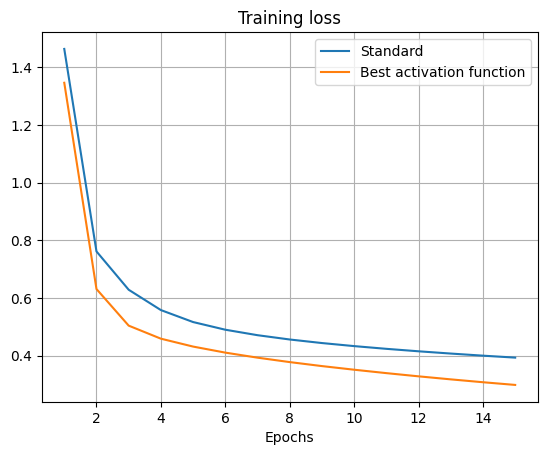

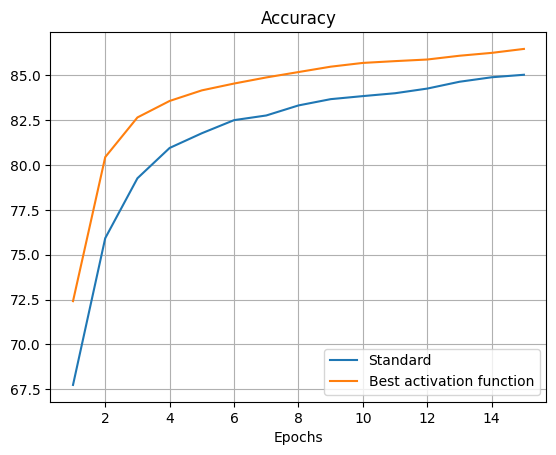

In [75]:
plot_2_histories(
    std_train_loss_history, af_train_loss_history, 'Training loss', 'Standard', 'Best activation function')

plot_2_histories(
    std_accuracy_history, af_accuracy_history, 'Accuracy', 'Standard', 'Best activation function')